# 1.0-cg-exploracion-regresion-p1.ipynb

**Pregunta 1:** ¿Cuántos viajes se iniciarán en una estación o zona en un periodo futuro?
**Objetivo:** Explorar la demanda histórica de MiBici por estación y fecha para identificar patrones temporales y preparar las características de un modelo de regresión.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from mibici.config import PROCESSED_DATA_DIR, FIGURES_DIR

%matplotlib inline
sns.set_theme(style="whitegrid")

2026-10-18 00:34:09.245 | INFO     | mibici.config:<module>:12 - PROJ_ROOT path is: /Users/carogzzleal/Documents/Maestria/3ertrimestre/MLOps/ProyectoMiBici/mibici-data-science


## 1. Carga de datos de viajes limpios y catálogo de estaciones

In [2]:
df_viajes = pd.read_parquet(PROCESSED_DATA_DIR / "viajes_limpios.parquet")
df_estaciones = pd.read_parquet(PROCESSED_DATA_DIR / "estaciones.parquet")

print(f"Total de viajes analizados: {len(df_viajes):,}")
print(f"Total de estaciones en catálogo: {len(df_estaciones):,}")
print(f"Estaciones de origen observadas: {df_viajes['Origen_Id'].nunique()}")
print(f"Periodo: {df_viajes['Inicio_del_viaje'].min()} a {df_viajes['Inicio_del_viaje'].max()}")

df_viajes.head()

Total de viajes analizados: 4,340,052
Total de estaciones en catálogo: 484
Estaciones de origen observadas: 471
Periodo: 2025-10-01 00:00:26 a 2026-09-30 23:59:48


,Viaje_Id,Usuario_Id,Genero,Anio_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,duracion_min
0,41060015,2664376,M,1979.0,2025-10-01 00:00:26,2025-10-01 00:08:55,244,46,8.483333
1,41060016,2371634,M,1976.0,2025-10-01 00:00:31,2025-10-01 00:07:33,31,6,7.033333
2,41060017,4527261,M,1992.0,2025-10-01 00:00:36,2025-10-01 00:07:03,73,39,6.450000
3,41060018,2524662,M,1996.0,2025-10-01 00:00:37,2025-10-01 00:13:20,21,248,12.716667
4,41060026,4577155,M,1990.0,2025-10-01 00:02:38,2025-10-01 00:29:37,81,35,26.983333


## 2. Exploración de actividad por estación

In [3]:
# Preparar fechas para el análisis
df_viajes["fecha"] = df_viajes["Inicio_del_viaje"].dt.normalize()
df_viajes["mes"] = df_viajes["Inicio_del_viaje"].dt.to_period("M")

# Calcular actividad por estación
df_actividad = (
    df_viajes.groupby("Origen_Id")
    .agg(
        dias_con_salidas=("fecha", "nunique"),
        meses_con_salidas=("mes", "nunique"),
        total_viajes=("Viaje_Id", "count")
    )
    .reset_index()
)

# Revisar estaciones fuera del catálogo
ids_catalogo = set(df_estaciones["estacion_id"])
ids_origen = set(df_viajes["Origen_Id"])

print(f"Estaciones fuera del catálogo: {len(ids_origen - ids_catalogo)}")
print(f"Estaciones del catálogo sin salidas: {len(ids_catalogo - ids_origen)}")
print(f"Estaciones con actividad en los 12 meses: {(df_actividad['meses_con_salidas'] == 12).sum()}")

df_actividad.describe().round(2)

Estaciones fuera del catálogo: 2
Estaciones del catálogo sin salidas: 15
Estaciones con actividad en los 12 meses: 354


,Origen_Id,dias_con_salidas,meses_con_salidas,total_viajes
count,471.00,471.00,471.00,471.00
mean,257.95,301.51,10.10,9214.55
std,148.62,113.96,3.55,10540.19
min,2.00,1.00,1.00,2.00
25%,133.50,331.00,12.00,2188.00
50%,259.00,364.00,12.00,5874.00
75%,383.50,365.00,12.00,12625.50
max,519.00,365.00,12.00,92012.00


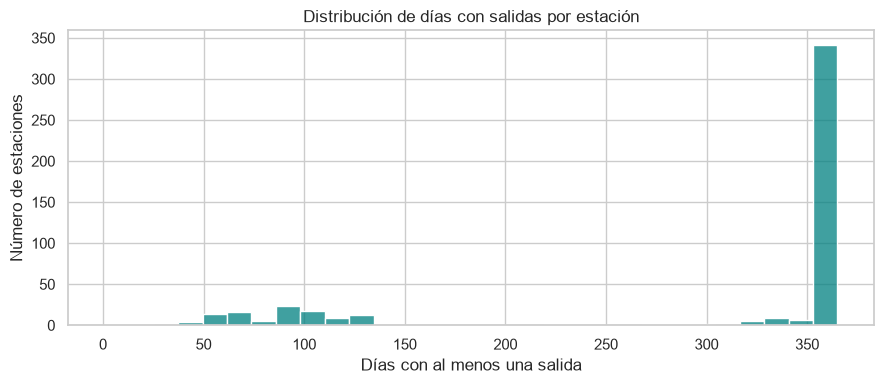

In [4]:
plt.figure(figsize=(9, 4))

sns.histplot(
    df_actividad["dias_con_salidas"],
    bins=30,
    color="teal"
)

plt.title("Distribución de días con salidas por estación")
plt.xlabel("Días con al menos una salida")
plt.ylabel("Número de estaciones")

plt.tight_layout()
plt.show()

## 3. Distribución temporal de la demanda

In [5]:
# Demanda diaria total
df_demanda_diaria = (
    df_viajes.groupby("fecha")
    .size()
    .reset_index(name="total_viajes")
)

df_demanda_diaria["dia_semana"] = df_demanda_diaria["fecha"].dt.dayofweek
df_demanda_diaria["mes"] = df_demanda_diaria["fecha"].dt.to_period("M")

# Promedio de viajes por día de la semana
demanda_semana = (
    df_demanda_diaria.groupby("dia_semana")["total_viajes"]
    .mean()
    .reindex(range(7))
)

# Total de viajes por mes
demanda_mensual = (
    df_demanda_diaria.groupby("mes")["total_viajes"]
    .sum()
)

print("Promedio diario de viajes por día de la semana:")
print(demanda_semana.round(0))

print("\nTotal de viajes por mes:")
print(demanda_mensual)

Promedio diario de viajes por día de la semana:
dia_semana
0    12420.0
1    13562.0
2    13431.0
3    13062.0
4    12768.0
5     9586.0
6     8376.0
Name: total_viajes, dtype: float64

Total de viajes por mes:
mes
2025-10    409536
2025-11    370241
2025-12    326417
2026-01    346634
2026-02    319053
2026-03    364811
2026-04    341708
2026-05    305102
2026-06    337556
2026-07    371616
2026-08    376300
2026-09    471078
Freq: M, Name: total_viajes, dtype: int64


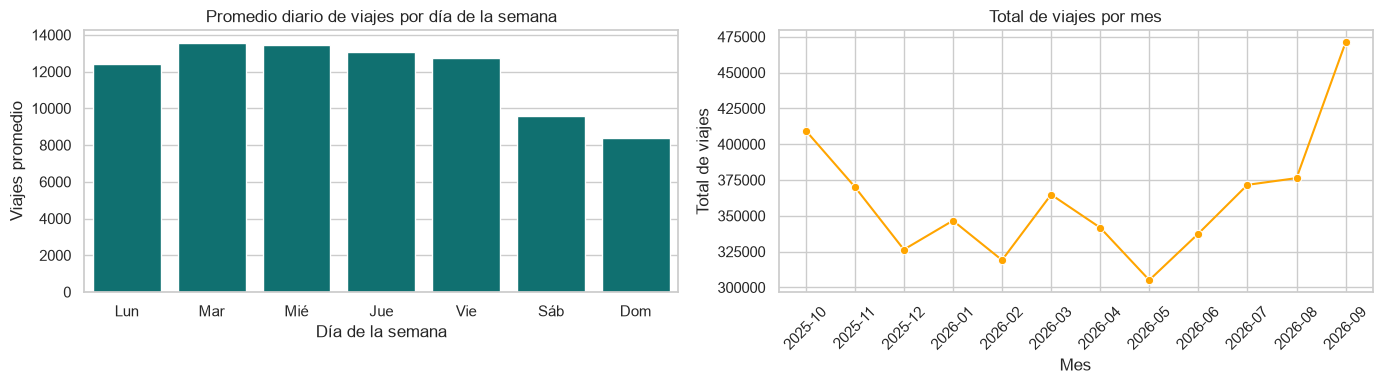

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Demanda por día de la semana
sns.barplot(
    x=["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"],
    y=demanda_semana.values,
    color="teal",
    ax=axes[0]
)

axes[0].set_title("Promedio diario de viajes por día de la semana")
axes[0].set_xlabel("Día de la semana")
axes[0].set_ylabel("Viajes promedio")

# Demanda mensual
sns.lineplot(
    x=demanda_mensual.index.astype(str),
    y=demanda_mensual.values,
    marker="o",
    color="orange",
    ax=axes[1]
)

axes[1].set_title("Total de viajes por mes")
axes[1].set_xlabel("Mes")
axes[1].set_ylabel("Total de viajes")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 4. Inspección de características para regresión

In [7]:
from mibici.features import (
    calcular_demanda_diaria_p1,
    preparar_demanda_diaria_p1,
    generar_caracteristicas_regresion_p1,
)

df_demanda_p1 = calcular_demanda_diaria_p1(
    df_viajes[["Inicio_del_viaje", "Origen_Id"]]
)

df_preparado_p1 = preparar_demanda_diaria_p1(df_demanda_p1)

df_features_p1 = generar_caracteristicas_regresion_p1(df_preparado_p1)

print(f"Estaciones seleccionadas: {df_features_p1['estacion_id'].nunique()}")
print(f"Registros generados: {len(df_features_p1):,}")

df_features_p1.head()

2026-10-18 03:25:23.084 | INFO     | mibici.features:calcular_demanda_diaria_p1:177 - Calculando demanda diaria por estación para P1...
2026-10-18 03:25:23.247 | SUCCESS  | mibici.features:calcular_demanda_diaria_p1:199 - Demanda diaria calculada: 142,013 registros para 471 estaciones.
2026-10-18 03:25:23.247 | INFO     | mibici.features:preparar_demanda_diaria_p1:237 - Preparando calendario diario de estaciones para P1...
2026-10-18 03:25:23.250 | INFO     | mibici.features:preparar_demanda_diaria_p1:267 - Estaciones seleccionadas: 348 (cobertura mínima: 95%).
2026-10-18 03:25:23.260 | INFO     | mibici.features:preparar_demanda_diaria_p1:296 - Combinaciones estación-día sin registros completadas con cero: 626.
2026-10-18 03:25:23.260 | SUCCESS  | mibici.features:preparar_demanda_diaria_p1:301 - Calendario P1 preparado: 127,020 registros para 348 estaciones.
2026-10-18 03:25:23.260 | INFO     | mibici.features:generar_caracteristicas_regresion_p1:330 - Generando características histór

,estacion_id,fecha,viajes_iniciados,dia_semana,mes,es_fin_de_semana,viajes_dia_anterior,viajes_hace_7_dias,promedio_7_dias,promedio_14_dias,viajes_hace_14_dias,viajes_hace_28_dias,promedio_28_dias,promedio_mismo_dia_4_semanas
0,2,2025-10-01,54,2,10,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2025-10-02,60,3,10,0,54.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,2025-10-03,71,4,10,0,60.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2,2025-10-04,37,5,10,1,71.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2,2025-10-05,26,6,10,1,37.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Evaluación y resultados de los modelos de regresión

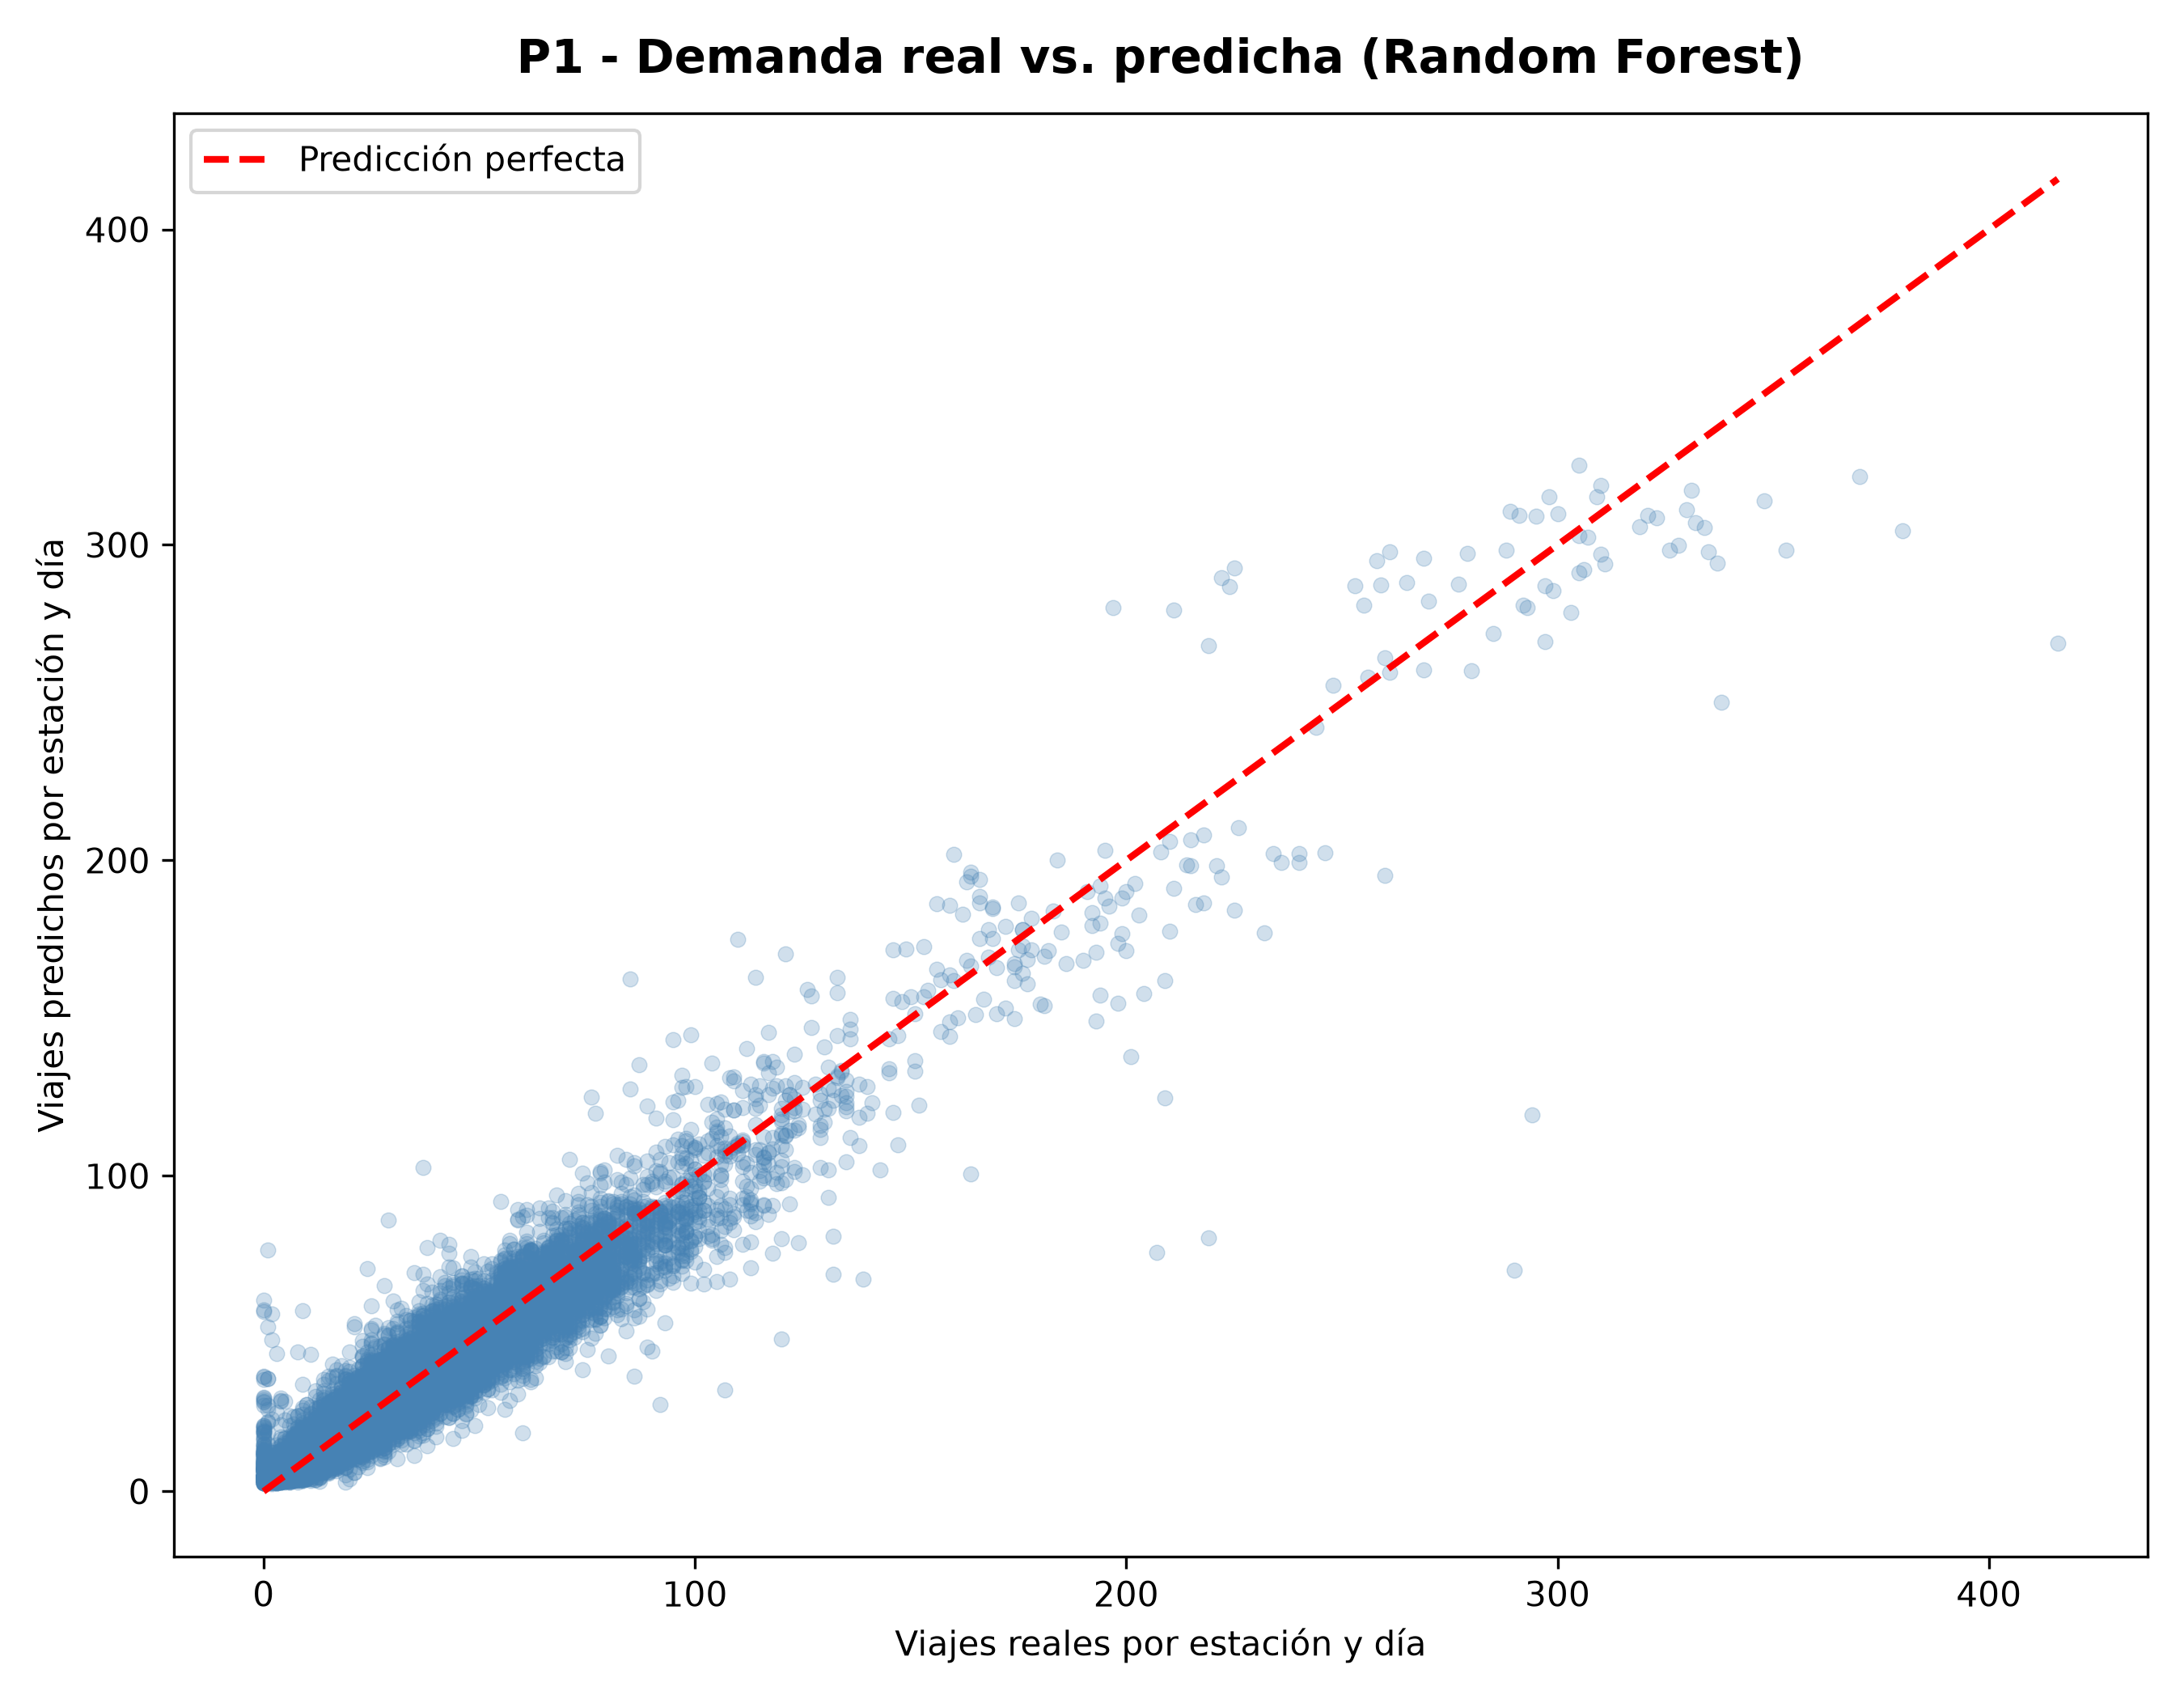

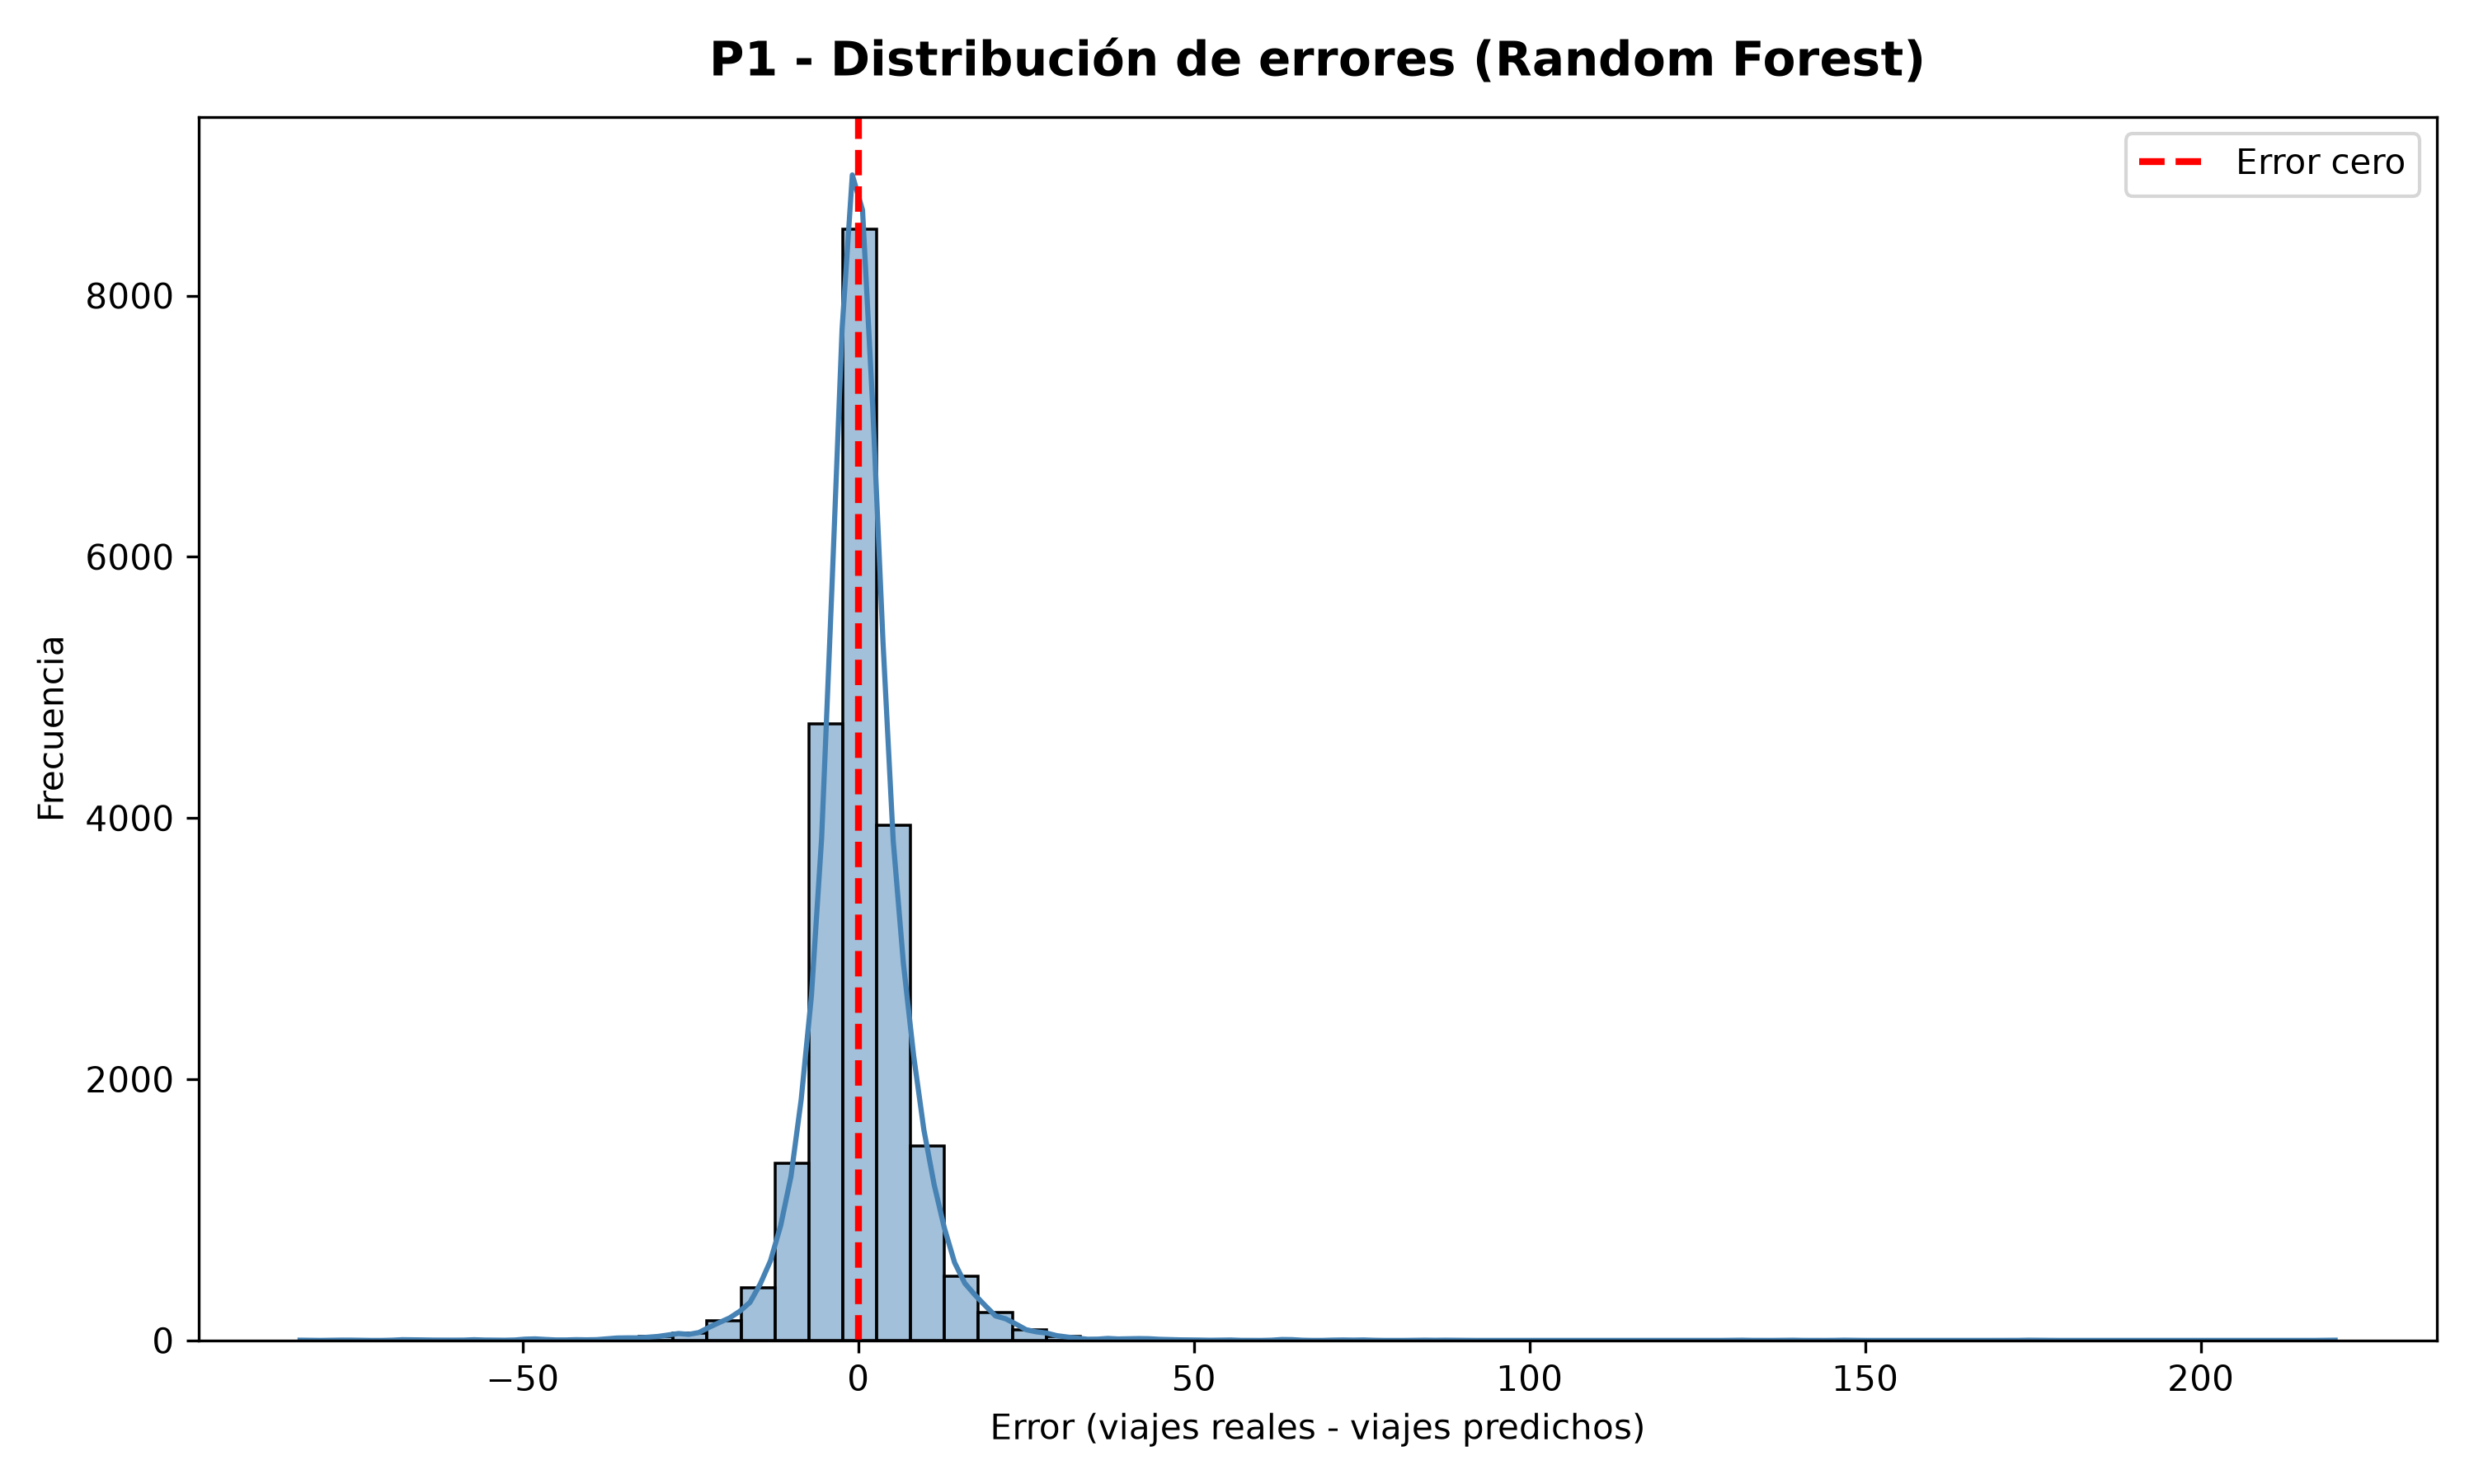

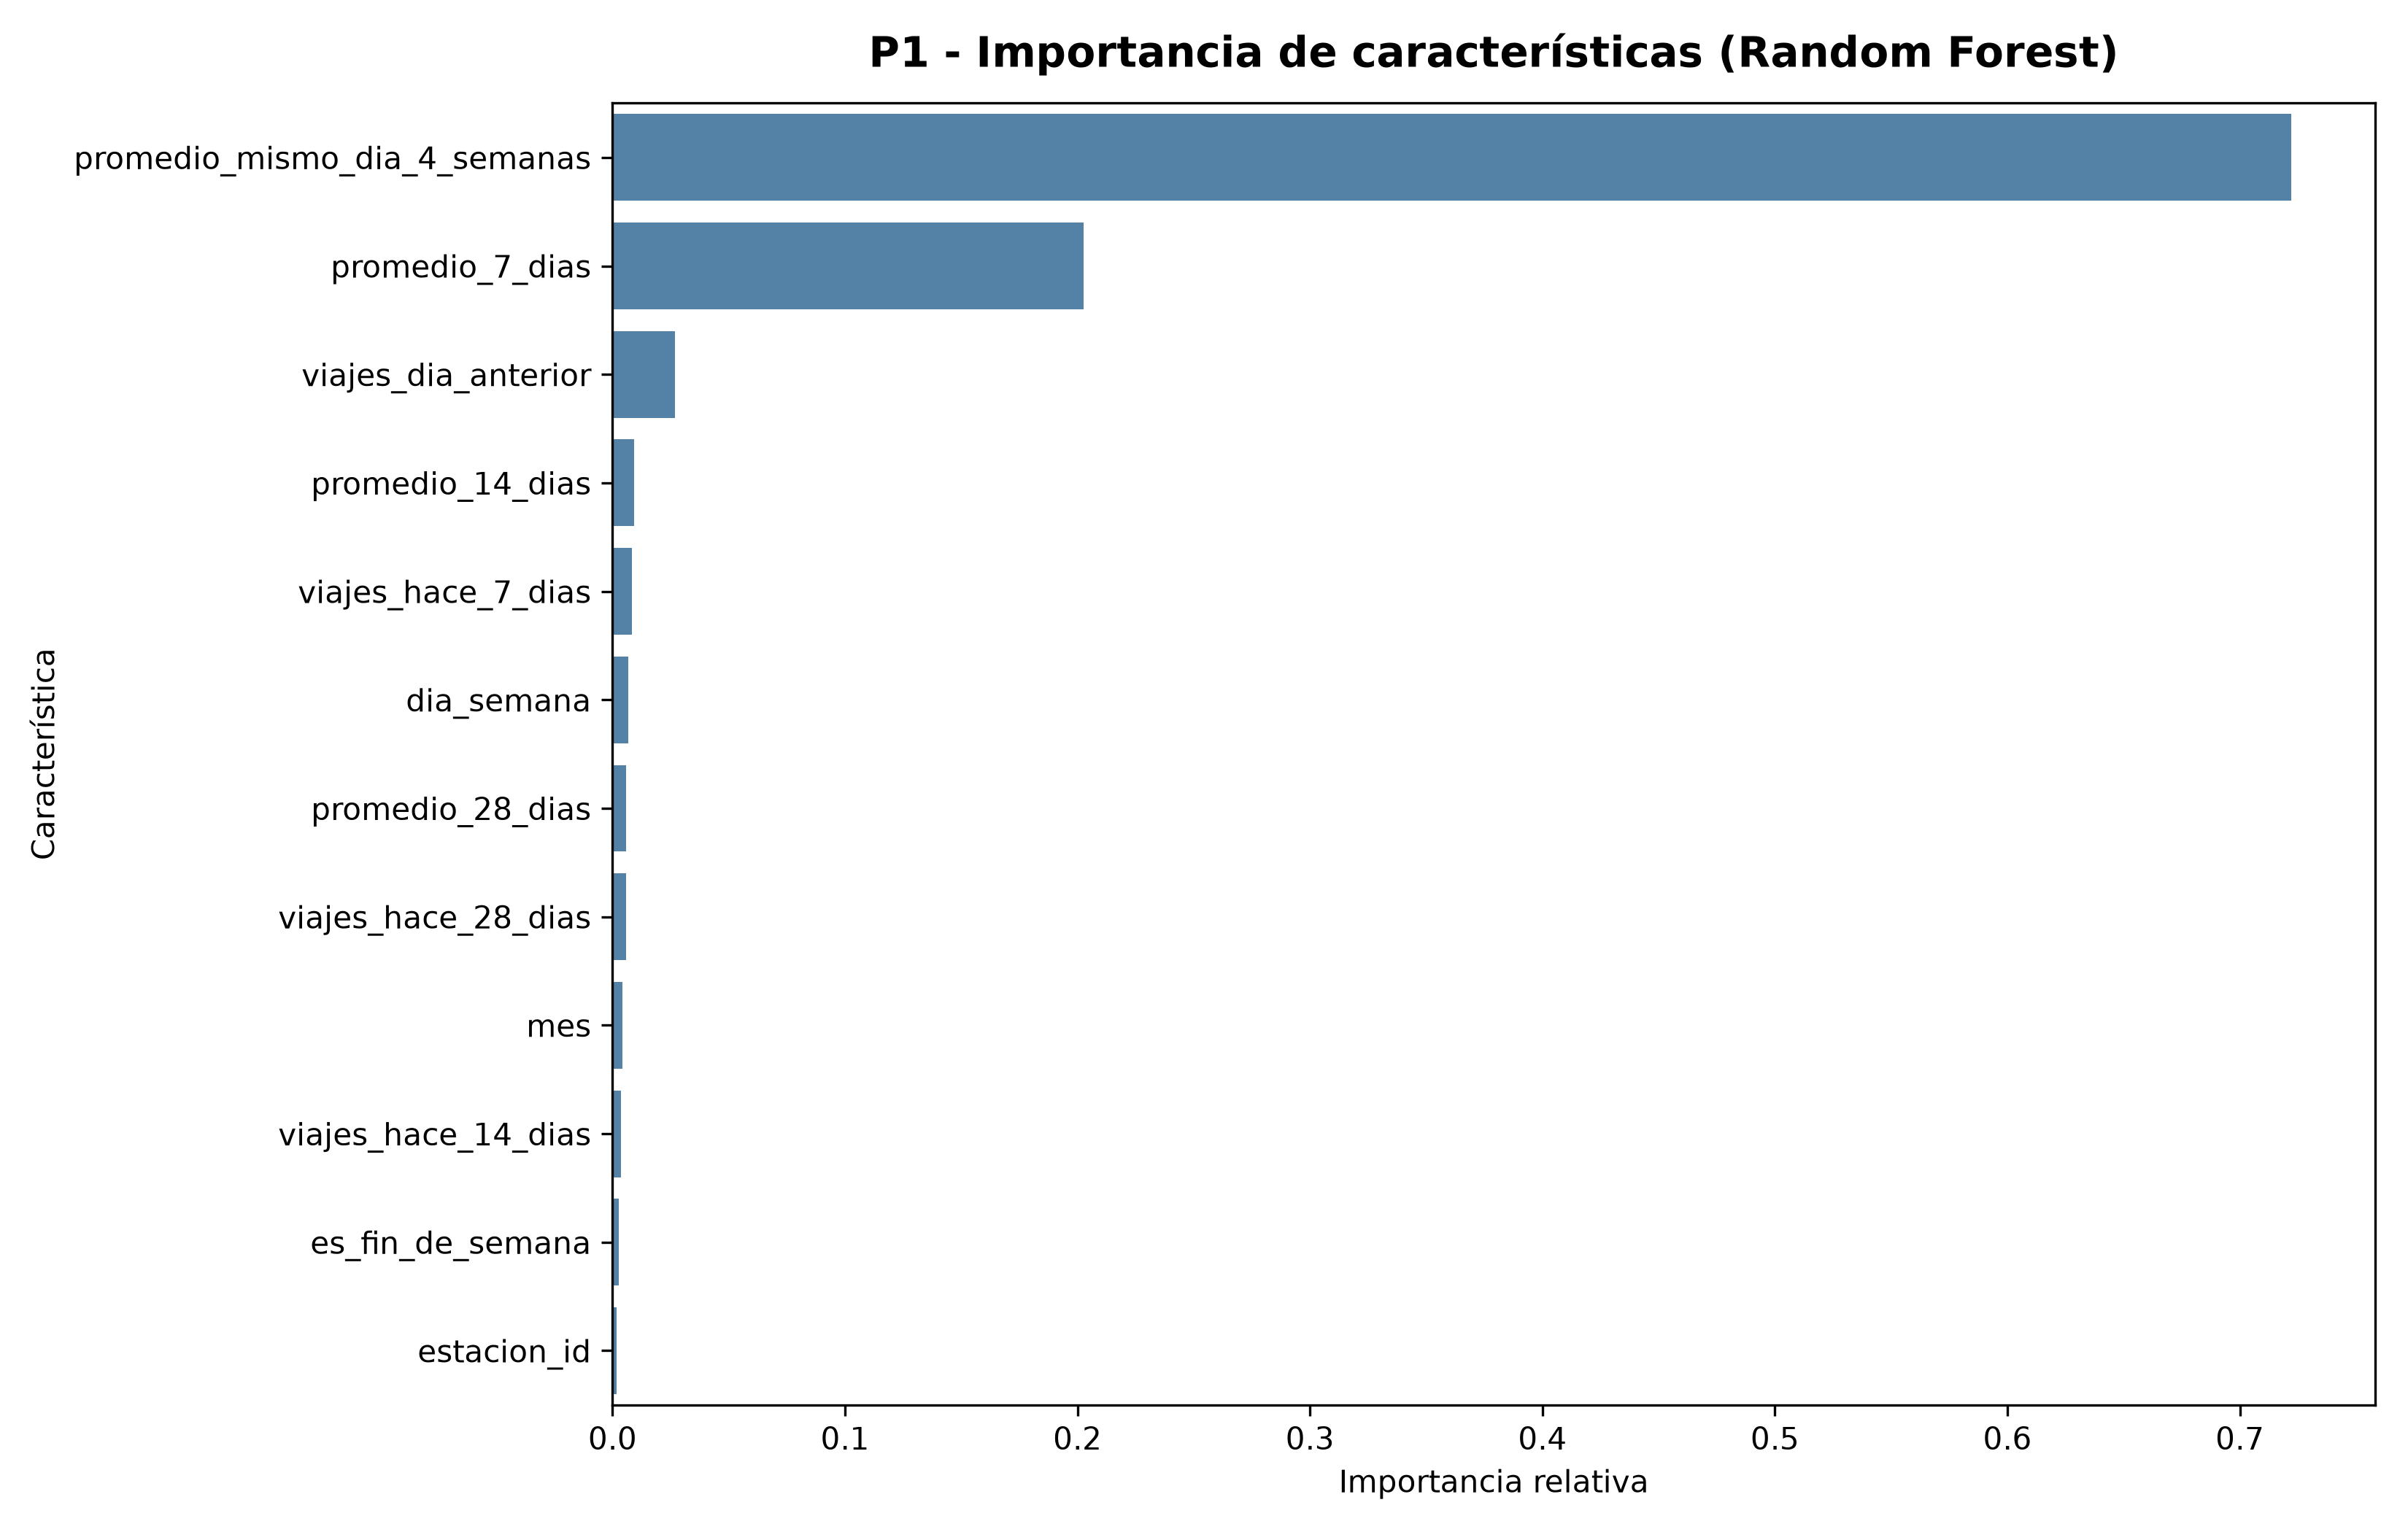

In [8]:
from IPython.display import display, Image

graficas_p1 = [
    "P1_random_forest_reales_vs_predichos.png",
    "P1_random_forest_distribucion_errores.png",
    "P1_random_forest_importancia_caracteristicas.png",
]

for grafica in graficas_p1:
    display(Image(filename=str(FIGURES_DIR / grafica), width=800))

### 5.2. Interpretación de las visualizaciones

**Valores reales vs. predichos.** Las predicciones presentan una relación
positiva con la demanda observada. Sin embargo, el modelo tiende a
subestimar algunos días con demanda especialmente elevada.

**Distribución de errores.** La mayoría de los errores se concentra
alrededor de cero, aunque existen valores extremos, principalmente
asociados con subestimaciones de la demanda.

**Importancia de características.** Las variables con mayor importancia
son el promedio de demanda del mismo día de la semana durante las cuatro
semanas anteriores y el promedio móvil de siete días. Esto respalda
la relevancia de los patrones semanales para predecir la demanda.

Las tres visualizaciones corresponden a la evaluación de validación
(julio-agosto de 2026).